# COMETE, round 2: the contour method for the anisotropy of Gaussian random fields

Companion notebook of *Gaussian random field's anisotropy using excursion sets* (Azaïs, Dalmao, De Castro, arXiv:2512.11085, revised version 2026).

The contour method estimates the anisotropy of a stationary Gaussian random field $X$ from a single binary image, the excursion set $\{X>u\}$, without knowing the level $u$, the mean or the variance. It uses the orientation of the unit normal $N(t)$ along the level set $\{X=u\}$: the Palm distribution of the normal depends on the field only through the covariance matrix $\Lambda$ of the gradient, and in dimension two the integrals
$$\mathcal C=\int_{\{X=u\}}\cos(2\Theta)\,\mathrm d\mathcal H^1,\qquad \mathcal S=\int_{\{X=u\}}\sin(2\Theta)\,\mathrm d\mathcal H^1$$
recover the direction $\theta_0$ and the strength $\kappa=\sqrt{1-\kappa_2^2/\kappa_1^2}$ of the anisotropy (Cabaña, 1987). The test of quasi-isotropy studentizes $(\mathcal C,\mathcal S)$ with the sample covariance of the same statistics computed on $N\times N$ cells of the window; its limit is $\chi^2(2)$ and no covariance model is needed.

This notebook goes through the pipeline of `comete_r2.py` on one field, runs a small Monte Carlo, shows how the figures of the paper are produced, and describes the Planck experiment. The complete runs of the paper take a few hours on a laptop (one configuration, Cauchy $\alpha=0.75$ at $\kappa=0.9$, takes about five hours by itself because of its $16{,}384\times16{,}384$ torus); the exact command lines are in the README, section "Reproducing the paper's runs".

In [1]:
import sys, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sys.path.insert(0, str(Path.cwd()))
from comete_r2 import (FieldConfig, CirculantSampler, base_correlation, level_set_segments, contour_statistics,
                       chi2_statistics, invert_g, invert_R, g_cabana, R_bierme_desolneux, lkc_estimate,
                       oracle_gradient, analyse_field, run_config, summarize)
from scipy.stats import f as fdist, chi2
sns.set_theme(context="notebook", style="darkgrid", font="sans-serif")
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.3 | pandas 3.0.6


## 1. Exact simulation of an anisotropic Gaussian field

The covariance is $r(t)=\rho(\|\mathbf A t\|)$ with $\rho$ an isotropic correlation (Gaussian $e^{-h^2}$, Matérn, or generalized Cauchy $(1+h^2/\alpha)^{-\alpha}$) and $\mathbf A=\mathrm{diag}(1/\ell_1,1/\ell_2)\mathbf P_{\theta_0}$. The length scales are chosen so that the gradient covariance is $\Lambda=\mathbf P_{-\theta_0}\mathrm{diag}(a^2,a^{-2})\mathbf P_{\theta_0}$ with $a=(1-\kappa^2)^{-1/4}$, whatever the family; hence $\kappa^2=1-a^{-4}$ and $\theta_0$ is the direction of largest gradient variance.

The field is sampled exactly on the $n\times n$ grid by circulant embedding: the covariance is evaluated on a torus twice as large ($2{,}048\times2{,}048$ for the $1{,}000\times1{,}000$ grid), its eigenvalues are computed by a two-dimensional FFT (they must be non-negative, which is checked; if they are not, the torus is doubled, which happens only for the Cauchy family with $\alpha=0.75$ at $\kappa=0.9$, sampled on a $16{,}384\times16{,}384$ torus), and one FFT of a complex white noise gives two independent fields.

torus 2048 x 2048, smallest eigenvalue / largest = -2.7e-16, two fields in 0.19 s
field mean 0.008, variance 0.992 (model: 0, 1)


empirical gradient covariance:
 [[0.932 0.804]
 [0.804 1.635]] 
model Lambda:
 [[0.978 0.845]
 [0.845 1.752]]
oracle estimate on the full field: kappa = 0.901 (true 0.9), theta0 = 0.992 (true 1.0)


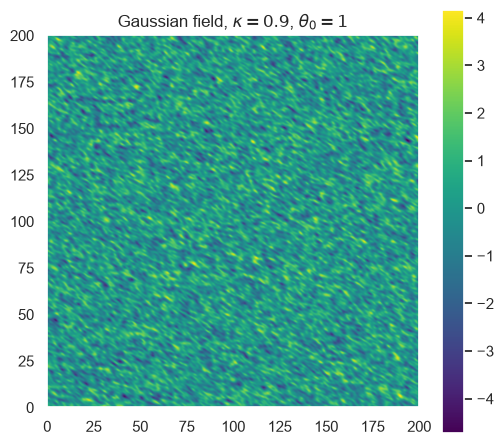

In [2]:
cfg = FieldConfig(model="gaussian", kappa=0.9, theta0=1.0, n=1000, unit_length=5)   # window [0, 200]^2, spacing 0.2
t0 = time.time()
sampler = CirculantSampler(cfg)
Z1, Z2 = sampler.sample_pair(np.random.default_rng(0))
print(f"torus {sampler.m} x {sampler.m}, smallest eigenvalue / largest = {sampler.min_eig:.1e}, two fields in {time.time()-t0:.2f} s")
print(f"field mean {Z1.mean():.3f}, variance {Z1.var():.3f} (model: 0, 1)")

# check of the gradient covariance against the model Lambda
kg, tg, Cov = oracle_gradient(Z1, cfg.spacing)
a = cfg.a; P = np.array([[np.cos(1.0), np.sin(1.0)], [-np.sin(1.0), np.cos(1.0)]])
Lambda = P.T @ np.diag([a**2, a**-2]) @ P
print("empirical gradient covariance:\n", Cov.round(3), "\nmodel Lambda:\n", Lambda.round(3))
print(f"oracle estimate on the full field: kappa = {kg:.3f} (true 0.9), theta0 = {tg:.3f} (true 1.0)")

fig, ax = plt.subplots(figsize=(6, 5.5))
im = ax.imshow(Z1, origin="lower", extent=[0, cfg.T, 0, cfg.T], cmap="viridis"); plt.colorbar(im, ax=ax)
ax.set_title(r"Gaussian field, $\kappa=0.9$, $\theta_0=1$"); ax.grid(False); plt.show()

The four covariance families of the paper (Gaussian, Matérn with $\nu=2.5$, generalized Cauchy with $\alpha=1.5$ and with $\alpha=0.75$), normalized to the same gradient covariance: the Matérn correlation decays exponentially and the Cauchy one polynomially ($h^{-2\alpha}$), so that distant parts of the window are dependent.

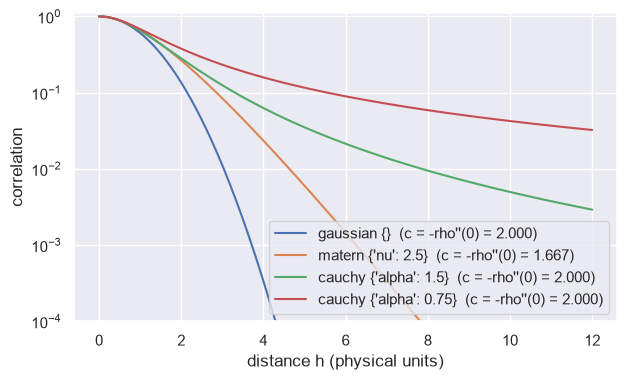

In [3]:
h = np.linspace(0, 12, 400)
fig, ax = plt.subplots(figsize=(7, 4))
for name, kw in [("gaussian", {}), ("matern", dict(nu=2.5)), ("cauchy", dict(alpha=1.5)), ("cauchy", dict(alpha=0.75))]:
    rho, c = base_correlation(name, **kw)
    ell = np.sqrt(c)                       # length scale giving -r''(0) = 1 (isotropic case a = 1)
    ax.plot(h, rho(h / ell), label=f"{name} {kw}  (c = -rho''(0) = {c:.3f})")
ax.set_xlabel("distance h (physical units)"); ax.set_ylabel("correlation"); ax.set_yscale("log"); ax.set_ylim(1e-4, 1.1); ax.legend(); plt.show()

## 2. Level set, normals and the contour statistics

The level set $\{X=u\}$ is extracted by marching squares (`contourpy`, the algorithm of `matplotlib.contour`) as a collection of polygonal paths. The integrals are computed exactly on the polygons: a segment of length $\ell$ with unit normal $(N_1,N_2)$ contributes $\ell\,(N_1^2-N_2^2)=\ell\cos 2\Theta$ to $\mathcal C$ and $2\ell N_1N_2=\ell\sin 2\Theta$ to $\mathcal S$. The statistics depend on $2\Theta$ only, so the orientation of the normal does not matter.

level set length 22322, 688 closed and 160 open paths
C = -5199.2, S = 11152.4, F = sqrt(C^2+S^2)/L = 0.5512
kappa_C = g^-1(F) = 0.898   (true 0.9;  g(0.9) = 0.5560)
theta_C = atan2(S, C)/2 = 1.004   (true 1.0)


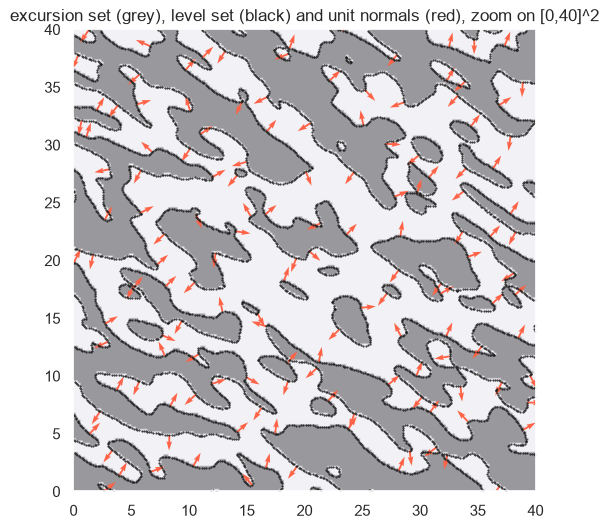

In [4]:
u = 0.0
seg = level_set_segments(Z1, u, cfg.spacing)
st = contour_statistics(seg, cfg.T, N_cells=10)
C, S, L = st["C"], st["S"], st["Ltot"]
F = np.sqrt(C**2 + S**2) / L
print(f"level set length {L:.0f}, {seg['n_closed']} closed and {seg['n_open']} open paths")
print(f"C = {C:.1f}, S = {S:.1f}, F = sqrt(C^2+S^2)/L = {F:.4f}")
print(f"kappa_C = g^-1(F) = {invert_g(F):.3f}   (true 0.9;  g(0.9) = {g_cabana(0.9):.4f})")
print(f"theta_C = atan2(S, C)/2 = {0.5*np.arctan2(S, C) % np.pi:.3f}   (true 1.0)")

# a zoom on the level set with a few normals
fig, ax = plt.subplots(figsize=(6.5, 6))
mid, vec, ln = seg["mid"], seg["vec"], seg["length"]
box = (mid[:, 0] < 40) & (mid[:, 1] < 40)
ax.imshow(Z1[:200, :200] > u, origin="lower", extent=[0, 40, 0, 40], cmap="Greys", alpha=0.35); ax.grid(False)
ax.plot(mid[box, 0], mid[box, 1], ".", ms=1, color="k")
idx = np.where(box)[0][::40]
nx, ny = vec[idx, 1] / ln[idx], -vec[idx, 0] / ln[idx]
ax.quiver(mid[idx, 0], mid[idx, 1], nx, ny, color="tomato", scale=30, width=0.004)
ax.set_title("excursion set (grey), level set (black) and unit normals (red), zoom on [0,40]^2"); plt.show()

## 3. The test of quasi-isotropy

The window is split into $N\times N$ cells; each cell has its own $(\mathcal C_i,\mathcal S_i)$, and their sample covariance $\widehat\Sigma_N$ estimates the covariance of $(\mathcal C,\mathcal S)$ up to the factor $N^2$. The statistic
$$Q_{n,N}=\frac{(\mathcal C,\mathcal S)\,\widehat\Sigma_N^{-1}(\mathcal C,\mathcal S)^\top}{N^2}$$
converges to $\chi^2(2)$ under quasi-isotropy. In finite samples the cell vectors are approximately independent Gaussian vectors, so $\frac{K-2}{2(K-1)}Q_{n,N}$ with $K=N^2$ follows Hotelling's $T^2$ law, that is $F(2,K-2)$; this is the threshold recommended in the paper. The scalar version $Q^{\rm iso}_{n,N}$ uses the pooled variance and is valid under strict isotropy.

anisotropic field (kappa = 0.9): Q_full = 8320.6, p (chi2) = 0.00e+00, p (T2) = 2.80e-95 | Q_iso = 10324.3


isotropic field: kappa_C = 0.100, Q_full = 0.55, p (chi2) = 0.758, p (T2) = 0.761


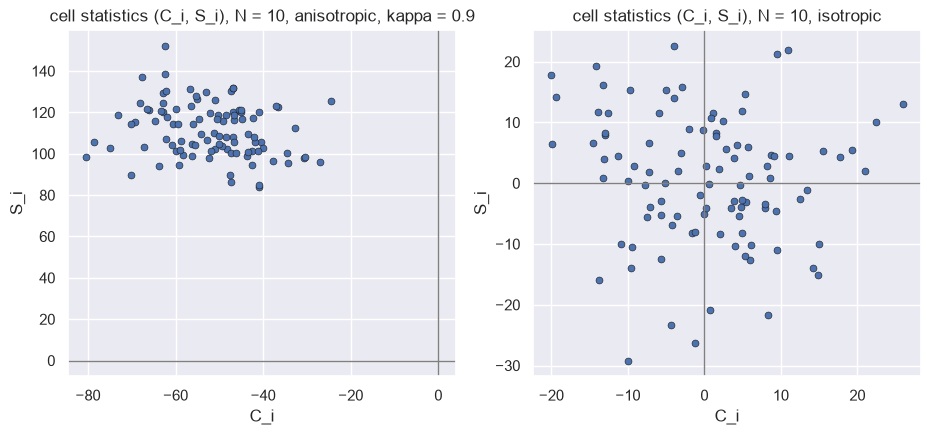

In [5]:
def T2_pvalue(Q, N):
    K = N * N
    return float(fdist.sf(Q * (K - 2) / (2.0 * (K - 1)), 2, K - 2))

for lab, Z in [("anisotropic field (kappa = 0.9)", Z1)]:
    seg = level_set_segments(Z, 0.0, cfg.spacing); st = contour_statistics(seg, cfg.T, 10)
    q = chi2_statistics(st["C"], st["S"], st["cell_C"], st["cell_S"])
    print(f"{lab}: Q_full = {q['Q_full']:.1f}, p (chi2) = {q['p_full']:.2e}, p (T2) = {T2_pvalue(q['Q_full'], 10):.2e} | Q_iso = {q['Q_scalar']:.1f}")

# an isotropic field for comparison
cfg0 = FieldConfig(model="gaussian", kappa=0.0, n=1000, unit_length=5)
Z0, _ = CirculantSampler(cfg0).sample_pair(np.random.default_rng(1))
seg0 = level_set_segments(Z0, 0.0, cfg0.spacing); st0 = contour_statistics(seg0, cfg0.T, 10)
q0 = chi2_statistics(st0["C"], st0["S"], st0["cell_C"], st0["cell_S"])
print(f"isotropic field: kappa_C = {invert_g(np.sqrt(st0['C']**2+st0['S']**2)/st0['Ltot']):.3f}, Q_full = {q0['Q_full']:.2f}, p (chi2) = {q0['p_full']:.3f}, p (T2) = {T2_pvalue(q0['Q_full'], 10):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (lab, stt) in zip(axes, [("anisotropic, kappa = 0.9", st), ("isotropic", st0)]):
    ax.scatter(stt["cell_C"], stt["cell_S"], s=25, edgecolor="k", linewidth=0.4)
    ax.axhline(0, color="grey", lw=1); ax.axvline(0, color="grey", lw=1)
    ax.set_title(f"cell statistics (C_i, S_i), N = 10, {lab}"); ax.set_xlabel("C_i"); ax.set_ylabel("S_i")
plt.show()

## 4. The LKC estimator and the oracle

The estimator of Biermé and Desolneux inverts the ratio $R(\kappa)=\sqrt{1-\kappa^2}/E(\kappa)^2$ from the area, the length and the Euler characteristic of the excursion set; the Euler characteristic is computed here by the Gauss-Bonnet formula on the polygons (sum of the turning angles divided by $2\pi$). The link $R$ is flat near zero ($R(0.5)/R(0)=0.992$), which is why this estimator does not resolve moderate anisotropy. The oracle uses the gradient of the field on the whole grid and is the benchmark of full observation.

In [6]:
for k in [0.1, 0.25, 0.5, 0.7, 0.9]:
    print(f"kappa = {k}: g(kappa) = {g_cabana(k):.4f}   R(kappa)/R(0) = {R_bierme_desolneux(k)/R_bierme_desolneux(0):.4f}")
area = float((Z1 > 0.0).sum()) * cfg.spacing**2
stat, kL = lkc_estimate(seg["euler_gb"], L, area, cfg.T)
print(f"\nanisotropic field: Euler characteristic (Gauss-Bonnet) = {seg['euler_gb']:.1f}, LKC statistic = {stat:.4f}, kappa_LKC = {kL:.3f}, kappa_grad (oracle) = {kg:.3f}, kappa_C = {invert_g(F):.3f}")

kappa = 0.1: g(kappa) = 0.0038   R(kappa)/R(0) = 1.0000
kappa = 0.25: g(kappa) = 0.0242   R(kappa)/R(0) = 0.9996
kappa = 0.5: g(kappa) = 0.1075   R(kappa)/R(0) = 0.9923
kappa = 0.7: g(kappa) = 0.2475   R(kappa)/R(0) = 0.9588
kappa = 0.9: g(kappa) = 0.5560   R(kappa)/R(0) = 0.7834

anisotropic field: Euler characteristic (Gauss-Bonnet) = -41.2, LKC statistic = 0.7112, kappa_LKC = 0.000, kappa_grad (oracle) = 0.901, kappa_C = 0.898


## 5. A small Monte Carlo

`run_config` simulates `nrep` fields in parallel and returns one row per field and level with every statistic (columns `kappa_C`, `theta_C`, `Q_full`, `p_full`, `Q_scalar`, `kappa_LKC_gb`, `kappa_grad`, and the suffixed columns `_N5`, `_N20`, ... for other numbers of cells). Forty fields per configuration here; the paper uses 5,000.

In [7]:
out = Path("results_notebook"); rows = []
t0 = time.time()
for k in [0.0, 0.5]:
    c = FieldConfig(model="gaussian", kappa=k, n=1000, unit_length=5)
    df = run_config(c, levels=[0.0, 1.0, 2.0], N_list=[10, 5, 20], n_rep=40, seed0=100, workers=2, out_dir=out, tag=f"demo_k{k}")
    rows.append(df)
demo = pd.concat(rows, ignore_index=True)
K = 100; demo["p_T2"] = fdist.sf(demo["Q_full"] * (K - 2) / (2 * (K - 1)), 2, K - 2)
print(f"{len(demo)} rows in {time.time()-t0:.0f} s")
demo.groupby(["kappa", "level"]).agg(kappa_C=("kappa_C", "mean"), kappa_C_sd=("kappa_C", "std"), theta_C_sd=("theta_C", "std"),
                                    kappa_LKC=("kappa_LKC_gb", "mean"), kappa_grad=("kappa_grad", "mean"),
                                    rej_T2=("p_T2", lambda p: np.mean(p < 0.05))).round(3)

  [demo_k0.0] 4/40 fields, 1s


  [demo_k0.0] 8/40 fields, 1s


  [demo_k0.0] 12/40 fields, 2s


  [demo_k0.0] 16/40 fields, 2s


  [demo_k0.0] 20/40 fields, 2s


...

  [demo_k0.5] 36/40 fields, 4s


  [demo_k0.5] 40/40 fields, 5s


[demo_k0.5] done: 120 rows in 5s (0.04s per row)


240 rows in 9 s


kappa_C  kappa_C_sd  theta_C_sd  kappa_LKC  kappa_grad  rej_T2
kappa level                                                                
0.0   0.0      0.141       0.029       0.957      0.391       0.126   0.050
      1.0      0.147       0.042       0.942      0.044       0.126   0.075
      2.0      0.174       0.060       0.952      0.000       0.126   0.050
0.5   0.0      0.493       0.012       0.027      0.278       0.497   1.000
      1.0      0.494       0.014       0.038      0.123       0.497   1.000
      2.0      0.494       0.023       0.053      0.019       0.497   1.000

## 6. The runs of the paper

The complete grid (four covariance families, $\kappa\in\{0,0.1,0.25,0.5,0.9\}$, three levels, 5,000 fields, $N\in\{5,10,20,25\}$, plus the window-size study) is launched with `resume_all.sh` (at most 4 workers, the cap set in `resume_grid.py`) or with the commands of the README. One configuration of 5,000 fields takes about three minutes with 7 workers, except Cauchy $\alpha=0.75$ at $\kappa=0.9$ (about five hours with 4 workers). The figures and tables of Section 4 are then produced by `python figures_r2.py`. The summary tables of the runs reported in the paper are in `results_summary/`.

In [8]:
summ = Path("results_summary")
if (summ / "summary_table.csv").exists():
    tab = pd.read_csv(summ / "summary_table.csv")
    display(tab[tab.kappa.isin([0.0, 0.25, 0.5, 0.9]) & (tab.level == 0)].round(3).to_string(index=False))
if (summ / "power_table.csv").exists():
    pw = pd.read_csv(summ / "power_table.csv")
    print("\nrejection rates at 5% (T2 threshold) against kappa, level u = 0:")
    display(pw[pw.level == 0].pivot(index="kappa", columns="family", values="chi2_T2").round(3))

'   family  kappa  level    n  kC_mean  kC_sd  th_sd  kLKC_mean  kLKC_sd  kgrad_mean  rej_full  rej_T2  rej_scalar\ncauchy075   0.00    0.0 5000    0.118  0.033  0.904      0.364    0.436       0.101     0.060   0.053       0.055\ncauchy075   0.25    0.0 5000    0.247  0.023  0.100      0.368    0.436       0.249     0.999   0.999       0.999\ncauchy075   0.50    0.0 5000    0.491  0.009  0.022      0.363    0.436       0.496     1.000   1.000       1.000\ncauchy075   0.90    0.0 5000    0.891  0.001  0.004      0.548    0.439       0.897     1.000   1.000       1.000\n cauchy15   0.00    0.0 5000    0.124  0.034  0.908      0.328    0.442       0.108     0.061   0.052       0.055\n cauchy15   0.25    0.0 5000    0.248  0.025  0.109      0.330    0.441       0.249     0.995   0.994       0.995\n cauchy15   0.50    0.0 5000    0.494  0.010  0.024      0.338    0.444       0.498     1.000   1.000       1.000\n cauchy15   0.90    0.0 5000    0.894  0.001  0.004      0.440    0.464       0


rejection rates at 5% (T2 threshold) against kappa, level u = 0:


family,cauchy075,cauchy15,gaussian,matern
kappa,,,,
0.00,0.053,0.052,0.057,0.057
0.10,0.102,0.095,0.091,0.097
0.25,0.999,0.994,0.957,0.993
0.50,1.000,1.000,1.000,1.000
0.90,1.000,1.000,1.000,1.000


## 7. The Planck experiment

`planck_r2.py` works on the Planck 2018 Commander temperature map (HEALPix, $N_{\rm side}=2048$). It removes the multipoles $\ell<40$, smooths the map to 15 arcmin, cuts sixteen flat patches of $20^\circ$ by a stereographic projection (conformal, so local isotropy is preserved), samples them on a $1{,}000\times1{,}000$ grid of 1.2 arcmin and applies the test at three levels. The same pipeline is applied to isotropic maps simulated from the best-fit spectrum (`synfast`), which gives the reference distribution of the statistics: the hypotheses of the asymptotic theory do not hold on the sphere, and the map must be kept at its native resolution before the projection (a degraded map interpolated onto the fine grid produces a faceted structure that the test reads as anisotropy).

The cells below run only if the map and the spectrum are in `~/Data/planck/` (see the README). They pass the parameters of the paper explicitly (`ell_min = 40`, `fwhm_out = 15.0`, `nside_out = 2048`, patches of 20 degrees, 1.2 arcmin per pixel), which are also the defaults of `planck_r2.py`; the stored outputs were produced with these values, and the three values of $\widehat\kappa_{\rm C}$ printed for the patch $(0,-50)$ are those of the Planck table of the paper. The pipeline at 10 arcmin and $N_{\rm side}=1024$ discussed in the paper (over-rejection on the simulated isotropic maps) is obtained with `python planck_r2.py sims --fwhm-out 10 --nside-out 1024`.

Planck data available: True


filtered map and one patch in 9 s
level +0 s: kappa_C = 0.110, theta_C = 1.66, p (T2, N=10) = 0.959, kappa_grad = 0.149
level +1 s: kappa_C = 0.131, theta_C = 2.89, p (T2, N=10) = 0.950, kappa_grad = 0.149
level -1 s: kappa_C = 0.263, theta_C = 1.74, p (T2, N=10) = 0.357, kappa_grad = 0.149


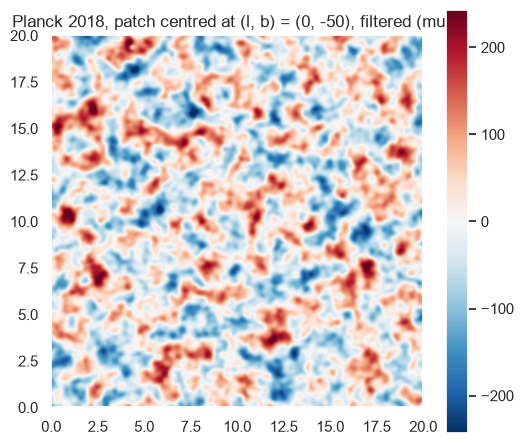

In [9]:
MAP = Path.home() / "Data" / "planck" / "COM_CMB_IQU-commander_2048_R3.00_full.fits"
CL = Path.home() / "Data" / "planck" / "COM_PowerSpect_CMB-base-plikHM-TTTEEE-lowl-lowE-lensing-minimum-theory_R3.01.txt"
RUN_PLANCK = MAP.exists() and CL.exists()
try:
    import healpy as hp
except ImportError:
    RUN_PLANCK = False
print("Planck data available:", RUN_PLANCK)
if RUN_PLANCK:
    import planck_r2 as P
    t0 = time.time()
    I = hp.read_map(MAP, field=0, dtype=np.float64) * 1e6
    alm = hp.map2alm(I, lmax=2000, iter=1)
    alm = P.filter_alm(alm, 2000, 40, 5.0, 15.0)
    mf = hp.alm2map(alm, nside=2048, lmax=2000)
    npix, th, ph = P.stereographic_grid(0.0, -50.0, 20.0, 1.2)
    Z = P.project(mf, th, ph, npix)
    rows = P.analyse_patch(Z, 1.2, N_list=(10, 20))
    print(f"filtered map and one patch in {time.time()-t0:.0f} s")
    for r in rows:
        print(f"level {r['level_sd']:+.0f} s: kappa_C = {r['kappa_C']:.3f}, theta_C = {r['theta_C']:.2f}, p (T2, N=10) = {T2_pvalue(r['Q_full'], 10):.3f}, kappa_grad = {r['kappa_grad']:.3f}")
    fig, ax = plt.subplots(figsize=(6, 5.5))
    im = ax.imshow(Z, origin="lower", extent=[0, 20, 0, 20], cmap="RdBu_r", vmin=-3*Z.std(), vmax=3*Z.std()); plt.colorbar(im, ax=ax)
    ax.set_title("Planck 2018, patch centred at (l, b) = (0, -50), filtered (muK)"); ax.grid(False); plt.show()

In [10]:
if RUN_PLANCK:
    # a short calibration: 4 simulated isotropic maps (the paper uses 100), same pipeline
    import multiprocessing as mp
    args = dict(lmax=2000, ell_min=40, fwhm_out=15.0, nside_out=2048, patch_deg=20.0, pix_arcmin=1.2, n_per_hemisphere=8, N_cells=[10, 20])
    t0 = time.time()
    with mp.get_context("fork").Pool(2) as pool:
        res = pool.map(P._sim_one, [(1000 + i, args) for i in range(4)])
    sims = pd.DataFrame([r for rr in res for r in rr]); sims["p_T2"] = [T2_pvalue(q, 10) for q in sims.Q_full]
    print(f"{sims.seed.nunique()} maps x 16 patches x 3 levels in {time.time()-t0:.0f} s; rejection at 5% (T2): {np.mean(sims.p_T2 < 0.05):.3f}; kappa_C mean {sims.kappa_C.mean():.3f}, 95% quantile {sims.kappa_C.quantile(.95):.3f}")
if (summ / "planck_summary.csv").exists():
    print("\nsummary of the paper's runs (100 simulated maps, 16 data patches), index = level in units of s:")
    display(pd.read_csv(summ / "planck_summary.csv", index_col=0).round(3))

4 maps x 16 patches x 3 levels in 8 s; rejection at 5% (T2): 0.052; kappa_C mean 0.236, 95% quantile 0.331

summary of the paper's runs (100 simulated maps, 16 data patches), index = level in units of s:


,data_rej05,data_kappa_mean,data_kappa_max,data_kappa_grad,sim_rej05,sim_rej05_chi2,sim_kappa_mean,sim_kappa_sd,sim_kappa_q95,sim_kappa_grad,n_sim,data_above_q95
0.0,0.125,0.227,0.316,0.191,0.054,0.059,0.225,0.059,0.318,0.197,1600.0,0.0
1.0,0.062,0.247,0.344,0.191,0.058,0.065,0.241,0.065,0.343,0.197,1600.0,1.0
-1.0,0.000,0.253,0.335,0.191,0.064,0.071,0.245,0.067,0.350,0.197,1600.0,0.0


## 8. Reproducibility

- Seeds: the Monte Carlo runs use `seed0 + i` for the $i$-th FFT (two fields per FFT); the simulated CMB maps use seeds 1000 to 1099.
- Software: numpy, scipy, contourpy, scikit-image (Euler numbers by counting, used as a check), seaborn (figures), healpy (Planck). Versions are in `requirements.txt`.
- Timing on a laptop (Apple silicon): about 0.5 s per $1{,}000\times1{,}000$ field and 0.05 s per level for the statistics; one simulated CMB map at $N_{\rm side}=2048$ with sixteen patches in about 3 s.
- The outputs of this notebook are written to `results_notebook/`.
- The exact command lines of every run of the paper, with their run times, are in `README.md`, section "Reproducing the paper's runs".